## Problem Statement

### Context

Business communities in the United States are facing high demand for human resources, but one of the constant challenges is identifying and attracting the right talent, which is perhaps the most important element in remaining competitive. Companies in the United States look for hard-working, talented, and qualified individuals both locally as well as abroad.

The Immigration and Nationality Act (INA) of the US permits foreign workers to come to the United States to work on either a temporary or permanent basis. The act also protects US workers against adverse impacts on their wages or working conditions by ensuring US employers' compliance with statutory requirements when they hire foreign workers to fill workforce shortages. The immigration programs are administered by the Office of Foreign Labor Certification (OFLC).

OFLC processes job certification applications for employers seeking to bring foreign workers into the United States and grants certifications in those cases where employers can demonstrate that there are not sufficient US workers available to perform the work at wages that meet or exceed the wage paid for the occupation in the area of intended employment.

### Objectives
* Facilitate the process of visa approvals.
* Recommend a suitable profile for the applicants for whom the visa should be certified or denied based on the drivers that significantly influence the case status.

### Data Dictionary
* `case_id`: ID of each visa application
* `continent`: Information of continent the employee
* `education_of_employee`: Information of education of the employee
* `has_job_experience`: Does the employee has any job experience? Y= Yes; N = No
* `requires_job_training`: Does the employee require any job training? Y = Yes; N = No
* `no_of_employees`: Number of employees in the employer's company
* `yr_of_estab`: Year in which the employer's company was established
* `region_of_employment`: Information of foreign worker's intended region of employment in the US.
* `prevailing_wage`: Average wage paid to similarly employed workers in a specific occupation in the area of intended employment. The purpose of the prevailing wage is to ensure that the foreign worker is not underpaid compared to other workers offering the same or similar service in the same area of employment.
* `unit_of_wage`: Unit of prevailing wage. Values include Hourly, Weekly, Monthly, and Yearly.
* `full_time_position`: Is the position of work full-time? Y = Full-Time Position; N = Part-Time Position
* `case_status`: Flag indicating if the Visa was certified or denied

## Installing and Importing the Necessary libraries

In [1]:
# Libraries to help with reading and manipulating data
import pandas as pd
import numpy as np

# Libaries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# To tune model, get different metric scores, and split data
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix,f1_score,make_scorer

# To help with model building
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    BaggingClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier
)

# To oversample and undersample data
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

# To do hyperparameter tuning
from sklearn.model_selection import RandomizedSearchCV

# To supress warnings
import warnings
warnings.filterwarnings("ignore")

## Loading the dataset

In [2]:
# Run the below code snippets if the dataset is present in the Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
# Load the dataset from the specified path into a pandas DataFrame
visa_data = pd.read_csv("/content/drive/MyDrive/PGP AIML Colab Notebooks/EasyVisa.csv")

In [4]:
# Create a copy of the original DataFrame to avoid modifying the raw data
data = visa_data.copy()

## Data Overview

### View the first and last 5 rows of the dataset.

In [5]:
# Display the first 5 rows of the DataFrame to get a quick overview of the data
data.head()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,EZYV01,Asia,High School,N,N,14513,2007,West,592.2029,Hour,Y,Denied
1,EZYV02,Asia,Master's,Y,N,2412,2002,Northeast,83425.6500,Year,Y,Certified
2,EZYV03,Asia,Bachelor's,N,Y,44444,2008,West,122996.8600,Year,Y,Denied
3,EZYV04,Asia,Bachelor's,N,N,98,1897,West,83434.0300,Year,Y,Denied
4,EZYV05,Africa,Master's,Y,N,1082,2005,South,149907.3900,Year,Y,Certified


In [6]:
# Display the last 5 rows of the DataFrame to check the end of the dataset
data.tail()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
25475,EZYV25476,Asia,Bachelor's,Y,Y,2601,2008,South,77092.57,Year,Y,Certified
25476,EZYV25477,Asia,High School,Y,N,3274,2006,Northeast,279174.79,Year,Y,Certified
25477,EZYV25478,Asia,Master's,Y,N,1121,1910,South,146298.85,Year,N,Certified
25478,EZYV25479,Asia,Master's,Y,Y,1918,1887,West,86154.77,Year,Y,Certified
25479,EZYV25480,Asia,Bachelor's,Y,N,3195,1960,Midwest,70876.91,Year,Y,Certified


### Understand the shape of the dataset.

In [7]:
# Print the shape of the DataFrame (number of rows, number of columns)
data.shape

(25480, 12)

* The dataset has 25480 rows and 12 columns

### Check the data types of the columns for the dataset

In [8]:
# Print a concise summary of the DataFrame, including data types and non-null values
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25480 entries, 0 to 25479
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   case_id                25480 non-null  object 
 1   continent              25480 non-null  object 
 2   education_of_employee  25480 non-null  object 
 3   has_job_experience     25480 non-null  object 
 4   requires_job_training  25480 non-null  object 
 5   no_of_employees        25480 non-null  int64  
 6   yr_of_estab            25480 non-null  int64  
 7   region_of_employment   25480 non-null  object 
 8   prevailing_wage        25480 non-null  float64
 9   unit_of_wage           25480 non-null  object 
 10  full_time_position     25480 non-null  object 
 11  case_status            25480 non-null  object 
dtypes: float64(1), int64(2), object(9)
memory usage: 2.3+ MB


* There are no null values in the data.

### Check the Statistical Summary

In [9]:
# Generate descriptive statistics of the numerical columns in the DataFrame
data.describe().T

,count,mean,std,min,25%,50%,75%,max
no_of_employees,25480.0,5667.043210,22877.928848,-26.0000,1022.00,2109.00,3504.0000,602069.00
yr_of_estab,25480.0,1979.409929,42.366929,1800.0000,1976.00,1997.00,2005.0000,2016.00
prevailing_wage,25480.0,74455.814592,52815.942327,2.1367,34015.48,70308.21,107735.5125,319210.27


* `no_of_employees`:
  1.   The average number of employees is around 5,667, but most companies are small, with 50% having fewer than 2,109 employees.
  2.   The presence of negative and extremely high values indicates outliers and possible data quality issues.
* `yr_of_estab`:
  1.   The average year of establishment is approximately 1979, with most companies founded between 1976 and 2005.
  2. Very old values i.e 1800 suggest potential outliers or incorrect data entries.
* `prevailing_wage`:
  1. The average prevailing wage is about 74,456 dollars.
  2. Extremely low and very high wage values indicate the presence of outliers.






### Dropping columns

- Let's drop the ID column before we proceed forward as it is a unique identified and will not add value to the analysis

In [10]:
# Drop the 'case_id' column as it is a unique identifier and not useful for modeling
data = data.drop(["case_id"], axis=1)

### Check Unique Values

In [11]:
# Display unique values in the 'continent' column
data["continent"].unique()

array(['Asia', 'Africa', 'North America', 'Europe', 'South America',
       'Oceania'], dtype=object)

In [12]:
# Display unique values in the 'education_of_employee' column
data["education_of_employee"].unique()

array(['High School', "Master's", "Bachelor's", 'Doctorate'], dtype=object)

In [13]:
# Display unique values in the 'has_job_experience' column
data["has_job_experience"].unique()

array(['N', 'Y'], dtype=object)

In [14]:
# Display unique values in the 'requires_job_training' column
data["requires_job_training"].unique()

array(['N', 'Y'], dtype=object)

In [15]:
# Display unique values in the 'no_of_employees' column
data["no_of_employees"].unique()

array([14513,  2412, 44444, ..., 24335, 48785, 40224])

In [16]:
# Display unique values in the 'yr_of_estab' column
data["yr_of_estab"].unique()

array([2007, 2002, 2008, 1897, 2005, 2012, 1994, 1924, 1995, 2004, 1963,
       2006, 1987, 1991, 2001, 1972, 2013, 1968, 1884, 1981, 1997, 2009,
       1998, 1880, 2000, 2010, 1965, 1909, 2011, 1989, 1933, 1960, 2003,
       1976, 1996, 1847, 1935, 1890, 1999, 1838, 1947, 1939, 1970, 1977,
       1982, 1943, 1956, 1864, 1974, 1985, 1984, 1971, 1913, 1969, 1818,
       1839, 1914, 1988, 1944, 1855, 1975, 1966, 1801, 1920, 1925, 1993,
       1992, 1979, 1986, 1931, 1962, 1954, 1868, 1859, 1946, 1950, 1869,
       1917, 2014, 1980, 1896, 1949, 1843, 1850, 1906, 1961, 1951, 1958,
       1912, 1983, 1948, 1945, 1978, 1898, 1923, 1911, 1851, 1865, 1849,
       1872, 1967, 1926, 1873, 1848, 2015, 1889, 1876, 1852, 1938, 1973,
       1959, 1927, 1990, 1930, 1922, 1940, 1878, 1934, 1834, 1928, 1800,
       1861, 1952, 1846, 1885, 1907, 1817, 1841, 1821, 1953, 1888, 1916,
       1886, 2016, 1932, 1915, 1937, 1866, 1919, 1921, 1910, 1854, 1875,
       1904, 1879, 1942, 1964, 1899, 1900, 1837, 18

In [17]:
# Display unique values in the 'region_of_employment' column
data["region_of_employment"].unique()

array(['West', 'Northeast', 'South', 'Midwest', 'Island'], dtype=object)

In [18]:
# Display unique values in the 'prevailing_wage' column
data["prevailing_wage"].unique()

array([   592.2029,  83425.65  , 122996.86  , ..., 146298.85  ,
        86154.77  ,  70876.91  ])

In [19]:
# Display unique values in the 'unit_of_wage' column
data["unit_of_wage"].unique()

array(['Hour', 'Year', 'Week', 'Month'], dtype=object)

In [20]:
# Display unique values in the 'full_time_position' column
data["full_time_position"].unique()

array(['Y', 'N'], dtype=object)

In [21]:
# Display unique values in the 'case_status' column
data["case_status"].unique()

array(['Denied', 'Certified'], dtype=object)

## Exploratory Data Analysis (EDA)


### Univariate Analysis

In [22]:
# Define a function to plot histogram and boxplot together for a feature
def histogram_boxplot(data, feature, figsize=(10,8), kde=False, bins=None):
    """
    Boxplot and histogram combined for a feature
    data: dataframe
    feature: column name
    figsize: size of figure
    kde: show density curve
    bins: number of bins for histogram
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,
        sharex=True,
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )
    sns.boxplot(data=data, x=feature, ax=ax_box2, showmeans=True, color="violet")
    if bins:
        sns.histplot(data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins)
    else:
        sns.histplot(data=data, x=feature, kde=kde, ax=ax_hist2)

In [23]:
# Define a function to plot count plots for a feature
def categorical_countplot(data, column, figsize=(8,4), rotation=0, order=None):
    """
    Plots a countplot for a categorical column.

    Parameters:
    data : pandas DataFrame
    column : column name (categorical)
    figsize : tuple, figure size
    rotation : rotation angle for x-axis labels
    order : list, custom category order (optional)
    """
    plt.figure(figsize=figsize)
    sns.countplot(data=data, x=column, order=order)
    plt.title(f'Distribution of {column}')
    plt.xticks(rotation=rotation)
    plt.show()

#### Observations on Number of Employees

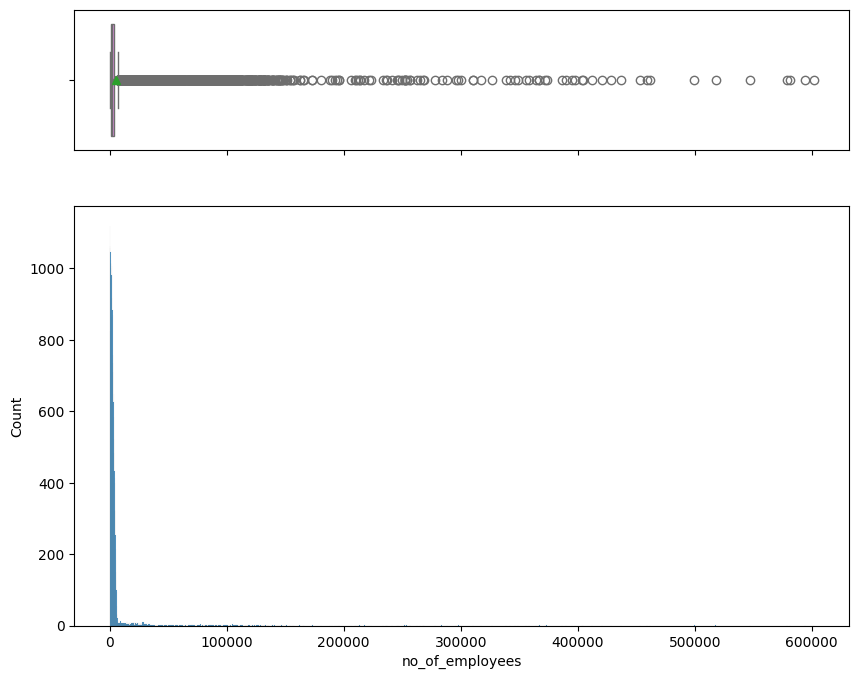

In [24]:
# Plot histogram and boxplot for 'no_of_employees' to visualize its distribution and identify outliers
histogram_boxplot(data, "no_of_employees")

* The `no_of_employees` variable is highly right-skewed, with most companies having a small number of employees.
* There are many extreme outliers, indicating a few very large companies.

#### Observation on Year of Establishment

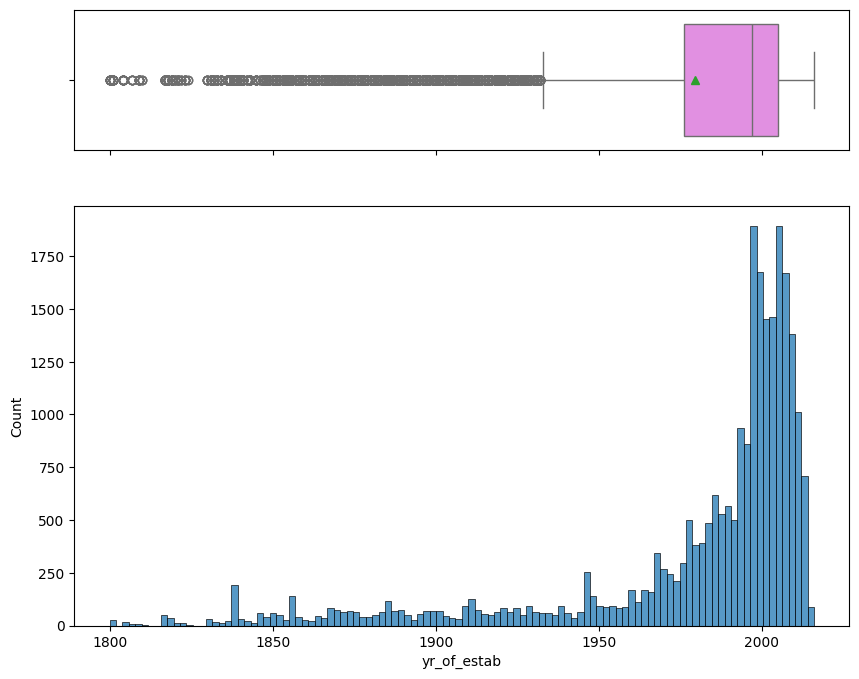

In [25]:
# Plot histogram and boxplot for 'yr_of_estab' to visualize its distribution and identify outliers
histogram_boxplot(data, "yr_of_estab")

* Most companies were established in recent years, with a high concentration after 1980.
* The distribution is left-skewed, indicating fewer very old companies and more newer ones.
* A few very old establishment years appear as outliers compared to the majority.

#### Observations on Prevailing Wage

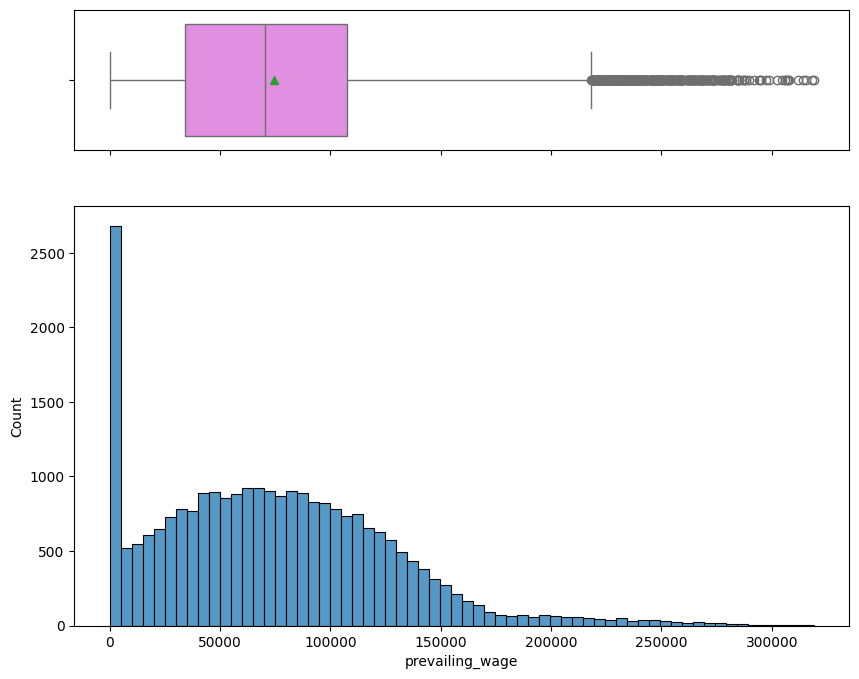

In [26]:
# Plot histogram and boxplot for 'prevailing_wage' to visualize its distribution and identify outliers
histogram_boxplot(data, "prevailing_wage")

* The prevailing_wage variable is right-skewed, with most wages concentrated at lower values.

* There are several high-end outliers, indicating a small number of very high-paying jobs.

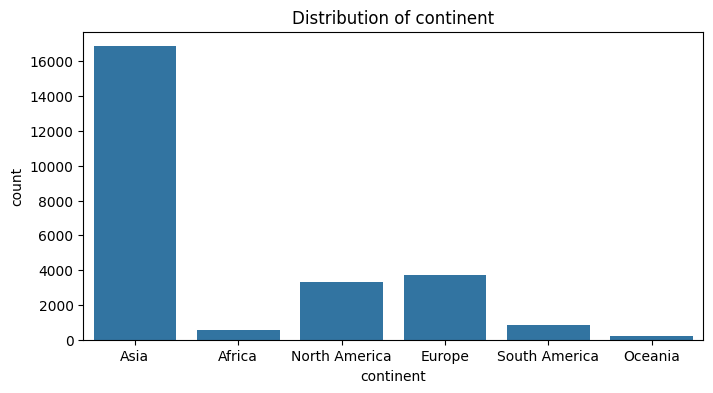

In [27]:
# Plot a countplot for the 'continent' column to show the distribution of applications by continent
categorical_countplot(data,'continent')

* Asia dominates the dataset, contributing the highest number of visa applications.
* Europe and North America have moderate representation compared to Asia.
* Africa, South America, and Oceania have very low application counts, indicating class imbalance across continents.

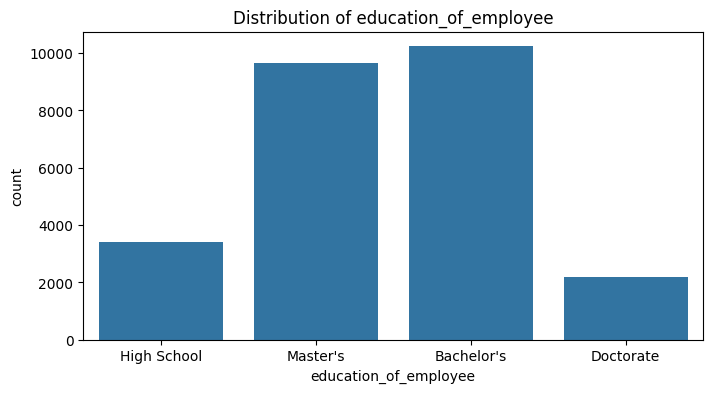

In [28]:
# Plot a countplot for 'education_of_employee' to visualize the distribution of education levels
categorical_countplot(data,'education_of_employee')

* The majority of employees are Bachelor’s degree holders, with Master’s degree holders also making up a large portion.
* Employees with High School education are much fewer compared to graduates.
* Doctorate holders form the smallest group in the dataset.

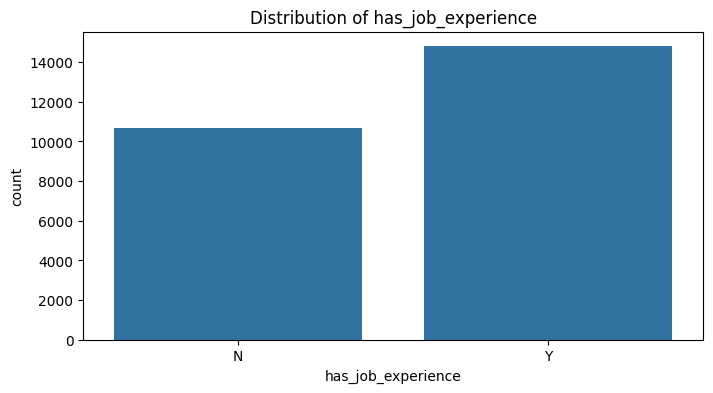

In [29]:
# Plot a countplot for 'has_job_experience' to visualize the distribution of job experience
categorical_countplot(data,'has_job_experience')

* More employees have prior job experience (Y) than those who do not (N).
* The difference is noticeable, but both experienced and non-experienced employees are well represented in the dataset.

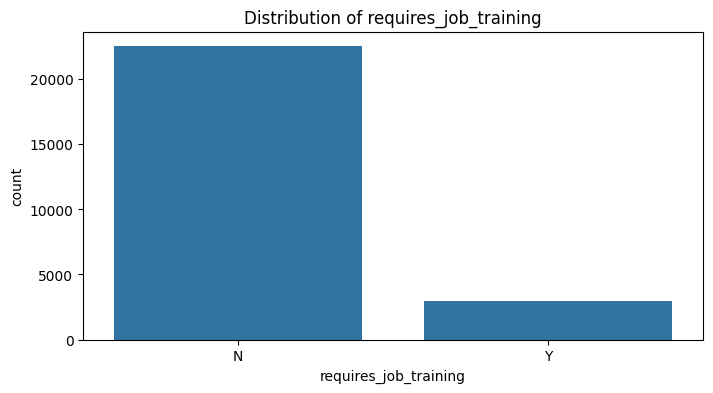

In [30]:
# Plot a countplot for 'requires_job_training' to visualize the distribution of training requirements
categorical_countplot(data,'requires_job_training')

* Most employees do not require job training (N).
* Only a small portion of employees require job training (Y), indicating most are already job-ready.

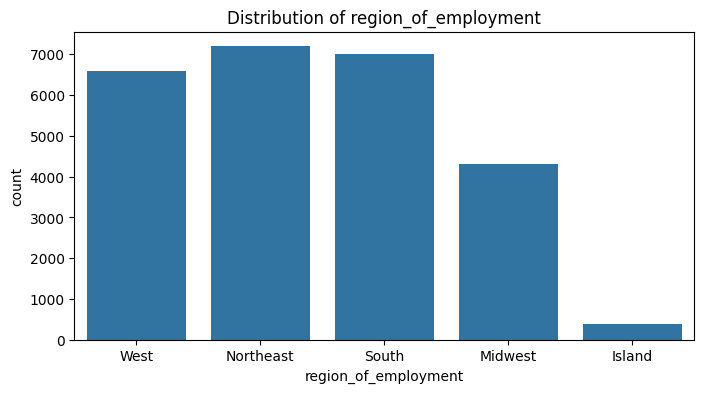

In [31]:
# Plot a countplot for 'region_of_employment' to visualize the distribution across employment regions
categorical_countplot(data,'region_of_employment')

* Most employees are employed in the Northeast, South, and West regions.
* The Midwest has a moderate number of employees compared to other regions.
* Island regions have very few employees, making it the least represented region.

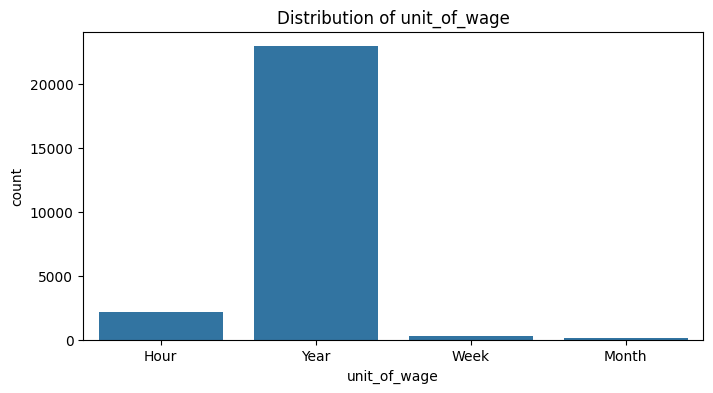

In [32]:
# Plot a countplot for 'unit_of_wage' to visualize the distribution of wage units
categorical_countplot(data,'unit_of_wage')

* Most wages are reported on a yearly basis, which is the dominant unit.
* Hourly wages are present but much fewer compared to yearly wages.
* Weekly and monthly wage units are very rare in the dataset.

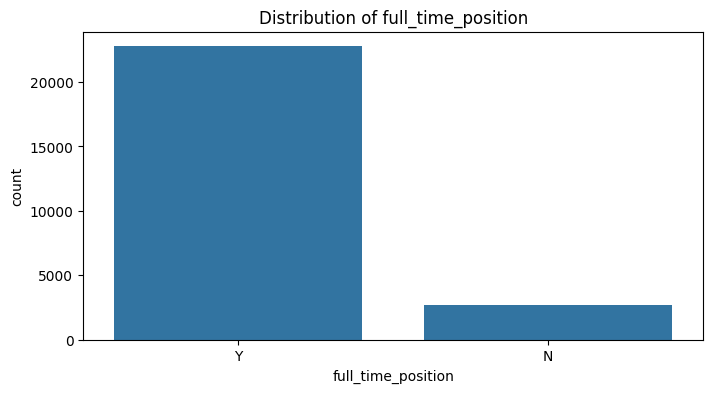

In [33]:
# Plot a countplot for 'full_time_position' to visualize the distribution of full-time positions
categorical_countplot(data,'full_time_position')

* Most job positions are full-time (Y).
* Only a small number of positions are not full-time (N), indicating full-time roles dominate the dataset.

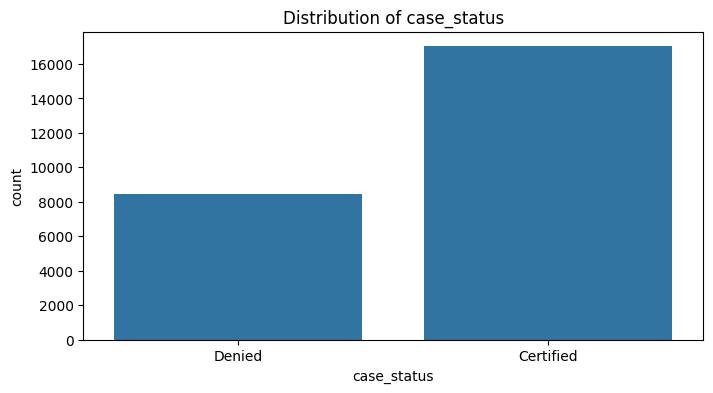

In [34]:
# Plot a countplot for 'case_status' to visualize the distribution of visa certification status
categorical_countplot(data,'case_status')

* More cases are Certified than Denied.
* This shows that a large portion of applications get approved compared to those rejected.

### Bivariate Analysis

In [35]:
# function to plot stacked_barplots
def stacked_barplot(data, predictor, target):
    """
    Print the category counts and plot a stacked bar chart

    data: dataframe
    predictor: independent variable
    target: target variable
    """
    count = data[predictor].nunique()
    sorter = data[target].value_counts().index[-1]
    tab1 = pd.crosstab(data[predictor], data[target], margins=True).sort_values(
        by=sorter, ascending=False
    )
    print(tab1)
    print("-" * 120)
    tab = pd.crosstab(data[predictor], data[target], normalize="index").sort_values(
        by=sorter, ascending=False
    )
    tab.plot(kind="bar", stacked=True, figsize=(count + 5, 5))
    plt.legend(
        loc="lower left", frameon=False,
    )
    plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
    plt.show()

In [36]:
# function to plot distributions wrt target
def distribution_plot_wrt_target(data, predictor, target):

    fig, axs = plt.subplots(2, 2, figsize=(12, 10))

    target_uniq = data[target].unique()

    axs[0, 0].set_title("Distribution of target for target=" + str(target_uniq[0]))
    sns.histplot(
        data=data[data[target] == target_uniq[0]],
        x=predictor,
        kde=True,
        ax=axs[0, 0],
        color="teal",
        stat="density",
    )

    axs[0, 1].set_title("Distribution of target for target=" + str(target_uniq[1]))
    sns.histplot(
        data=data[data[target] == target_uniq[1]],
        x=predictor,
        kde=True,
        ax=axs[0, 1],
        color="orange",
        stat="density",
    )

    axs[1, 0].set_title("Boxplot w.r.t target")
    sns.boxplot(data=data, x=target, y=predictor, ax=axs[1, 0], palette="gist_rainbow")

    axs[1, 1].set_title("Boxplot (without outliers) w.r.t target")
    sns.boxplot(
        data=data,
        x=target,
        y=predictor,
        ax=axs[1, 1],
        showfliers=False,
        palette="gist_rainbow",
    )

    plt.tight_layout()
    plt.show()

#### Correlation check

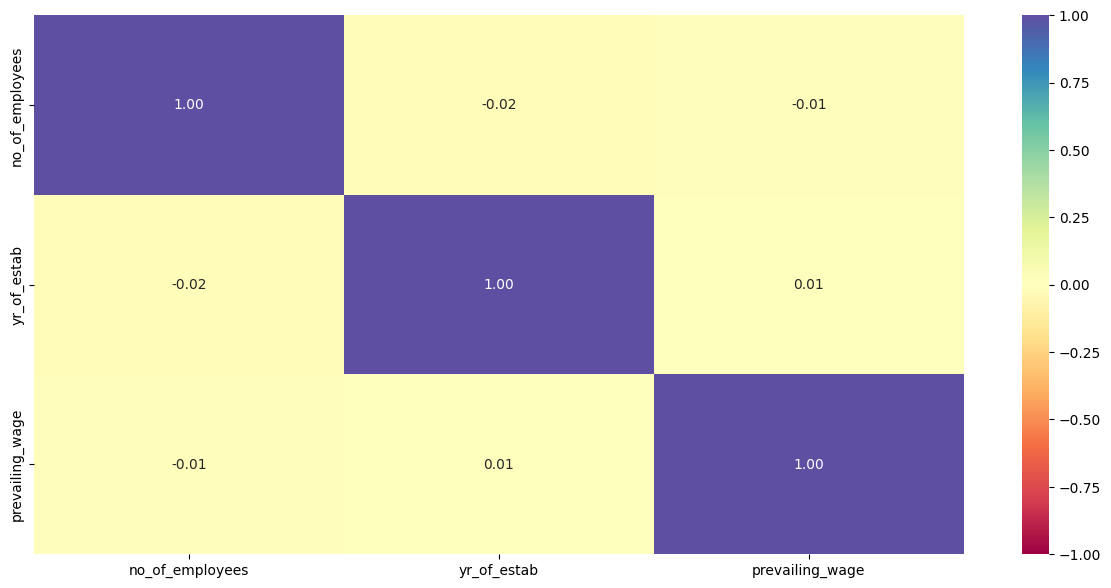

In [37]:
# Correlation plot to visualize the relationships between numerical variables
plt.figure(figsize=(15, 7))
sns.heatmap(data.corr(numeric_only = True), annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="Spectral")
plt.show()

* All variables show very weak correlations with each other (values close to 0).
* `Education`, `No of Employees`, `Year of Establishment`, and `Prevailing Wage` are mostly independent and do not strongly influence one another.

#### Case Status vs Continent

case_status    Certified  Denied    All
continent                              
All                17018    8462  25480
Asia               11012    5849  16861
North America       2037    1255   3292
Europe              2957     775   3732
South America        493     359    852
Africa               397     154    551
Oceania              122      70    192
------------------------------------------------------------------------------------------------------------------------


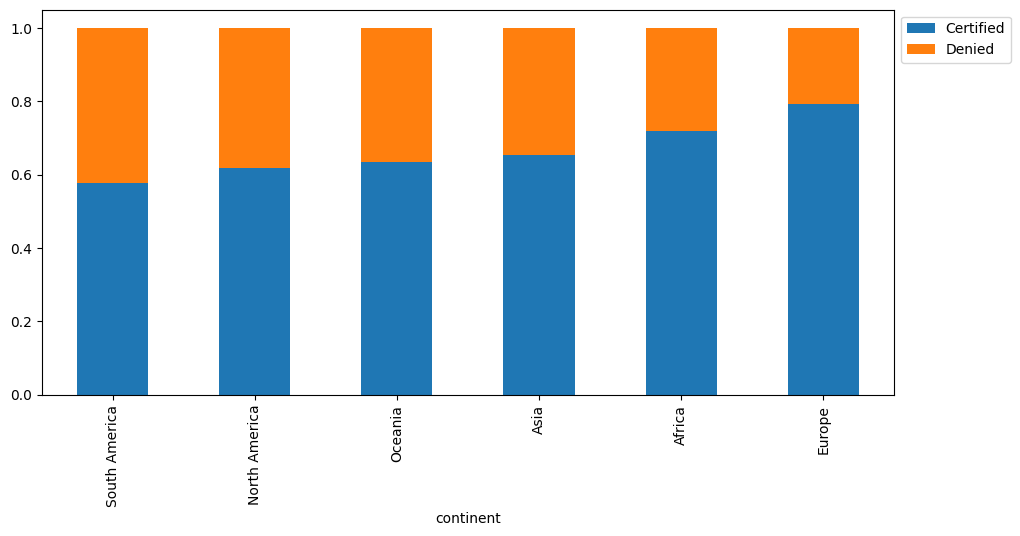

In [38]:
# Create a stacked bar plot to show the distribution of 'case_status' across different 'continent' categories
stacked_barplot(data, 'continent', 'case_status')

* Europe has the highest certification rate, with the fewest denials.
* South America has the lowest certification rate and a higher proportion of denials.
* Overall, certification rates are higher than denials across all continents, but they vary by region.

#### Case Status vs Requires Job Training

case_status            Certified  Denied    All
requires_job_training                          
All                        17018    8462  25480
N                          15012    7513  22525
Y                           2006     949   2955
------------------------------------------------------------------------------------------------------------------------


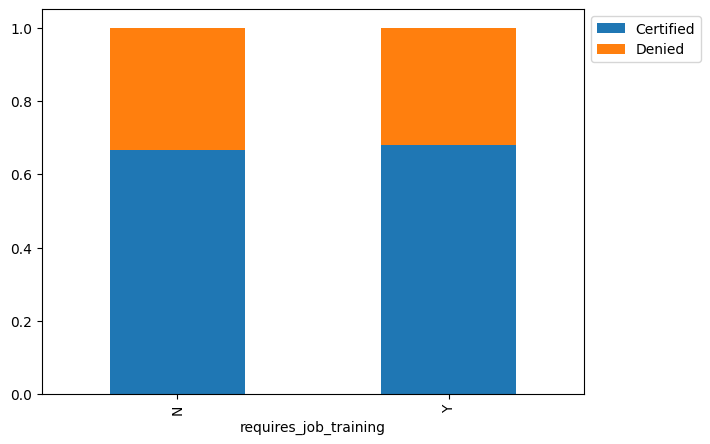

In [39]:
# Create a stacked bar plot to show the distribution of 'case_status' based on 'requires_job_training'
stacked_barplot(data, 'requires_job_training', 'case_status')

* Certification rates are almost the same for jobs that require training and those that do not.
* Requiring job training does not strongly affect whether a case is certified or denied.

#### Case Status vs Region of Employment

case_status           Certified  Denied    All
region_of_employment                          
All                       17018    8462  25480
Northeast                  4526    2669   7195
West                       4100    2486   6586
South                      4913    2104   7017
Midwest                    3253    1054   4307
Island                      226     149    375
------------------------------------------------------------------------------------------------------------------------


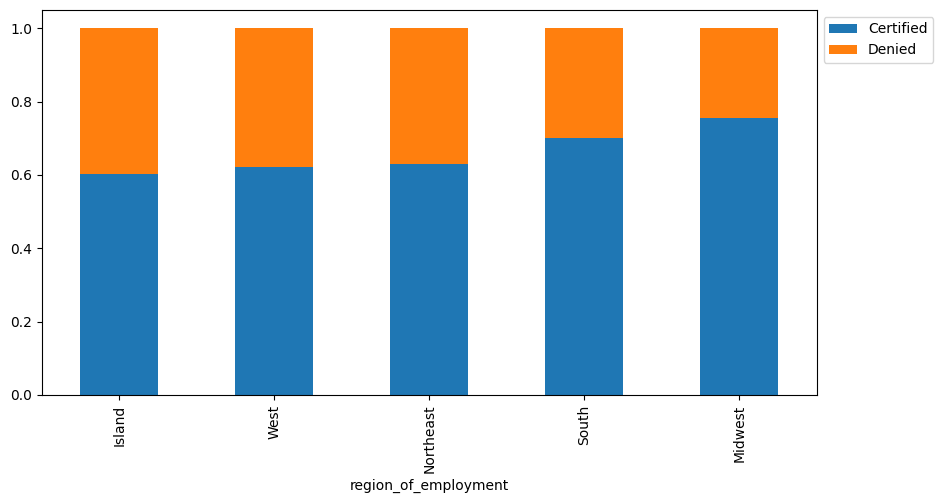

In [40]:
# Create a stacked bar plot to show the distribution of 'case_status' across different 'region_of_employment' categories
stacked_barplot(data, 'region_of_employment', 'case_status')

* Midwest has the highest certification rate, followed by the South.
* Island and West regions have comparatively lower certification rates.
* Overall, certified cases are higher than denied cases in all regions.

#### Case Status vs Unit of Wage

case_status   Certified  Denied    All
unit_of_wage                          
All               17018    8462  25480
Year              16047    6915  22962
Hour                747    1410   2157
Week                169     103    272
Month                55      34     89
------------------------------------------------------------------------------------------------------------------------


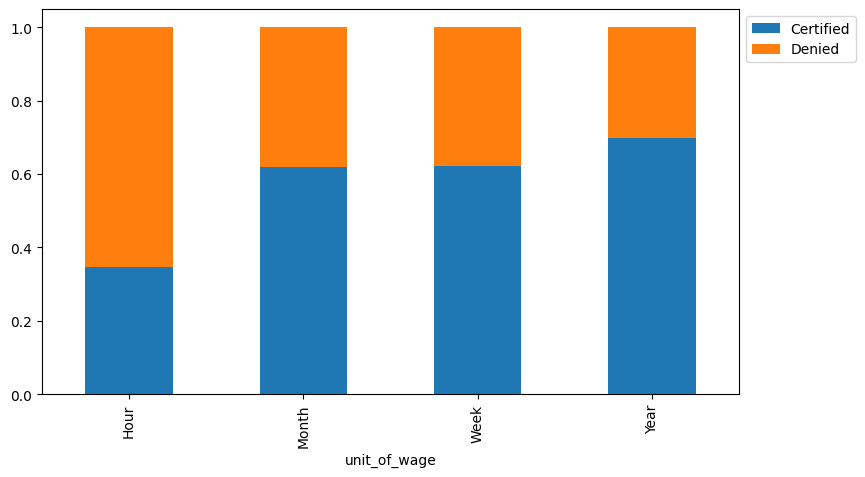

In [41]:
# Create a stacked bar plot to show the distribution of 'case_status' across different 'unit_of_wage' categories
stacked_barplot(data, 'unit_of_wage', 'case_status')

* Jobs with yearly wages have the highest certification rate.
* Hourly wage jobs have the lowest certification rate and the highest denials.



#### Case Status vs Full Time Position

case_status         Certified  Denied    All
full_time_position                          
All                     17018    8462  25480
Y                       15163    7610  22773
N                        1855     852   2707
------------------------------------------------------------------------------------------------------------------------


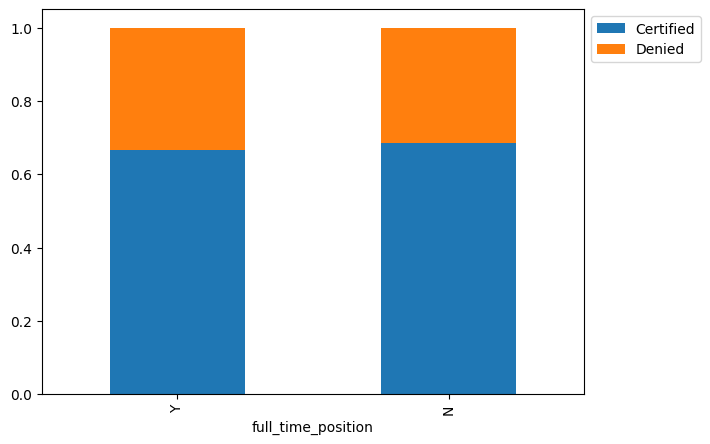

In [42]:
# Create a stacked bar plot to show the distribution of 'case_status' based on 'full_time_position'
stacked_barplot(data, 'full_time_position', 'case_status')

* Certification rates are almost the same for full-time and non–full-time positions.
* Being a full-time position does not significantly impact whether a case is certified or denied.

#### Case Status vs No of employees

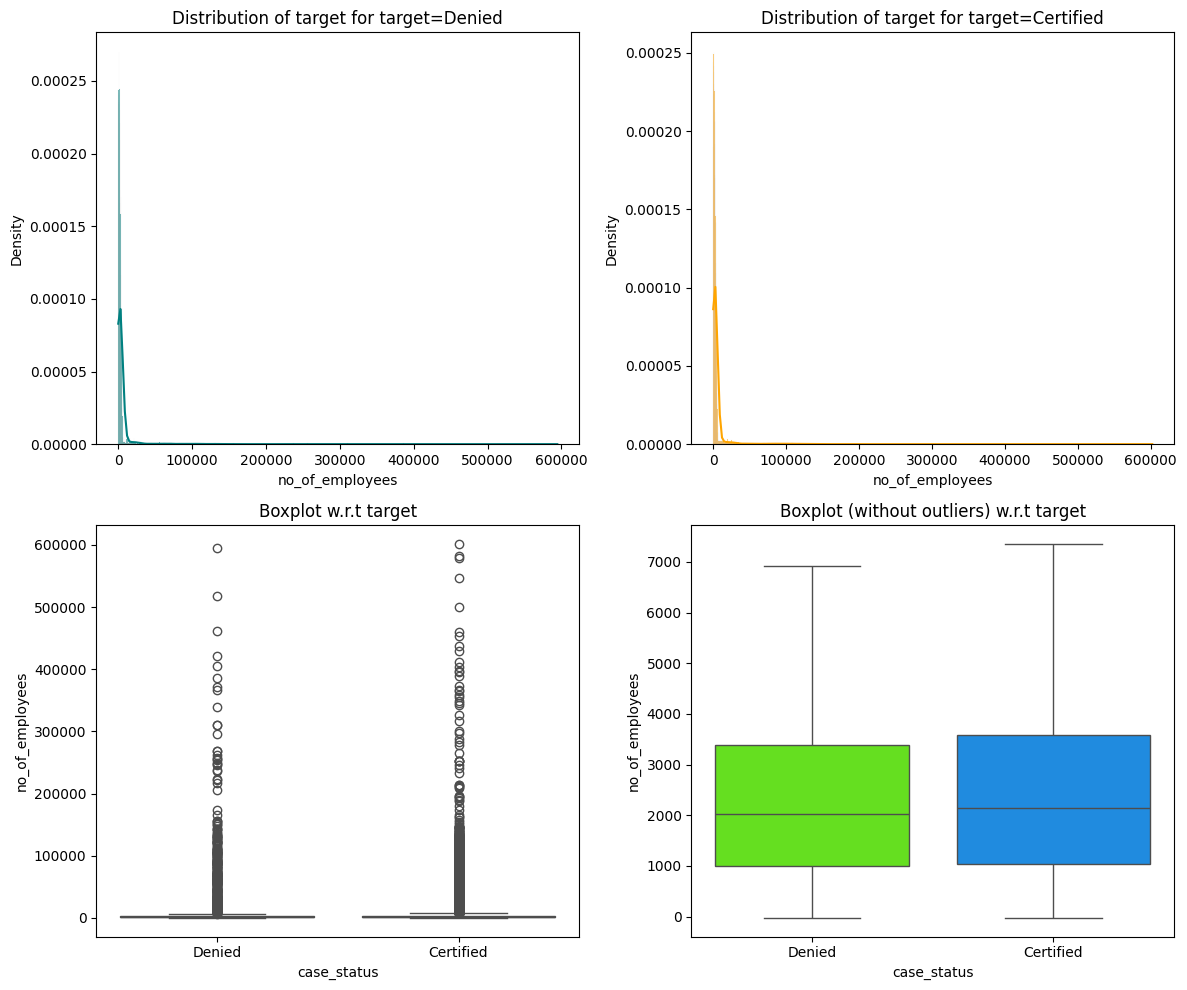

In [43]:
# Plot the distribution of 'no_of_employees' with respect to 'case_status' to understand their relationship
distribution_plot_wrt_target(data, 'no_of_employees', 'case_status')

* For both Denied and Certified cases, the number of employees is highly right-skewed, with many small companies and a few very large ones.


#### Case Status vs Prevailing Wage

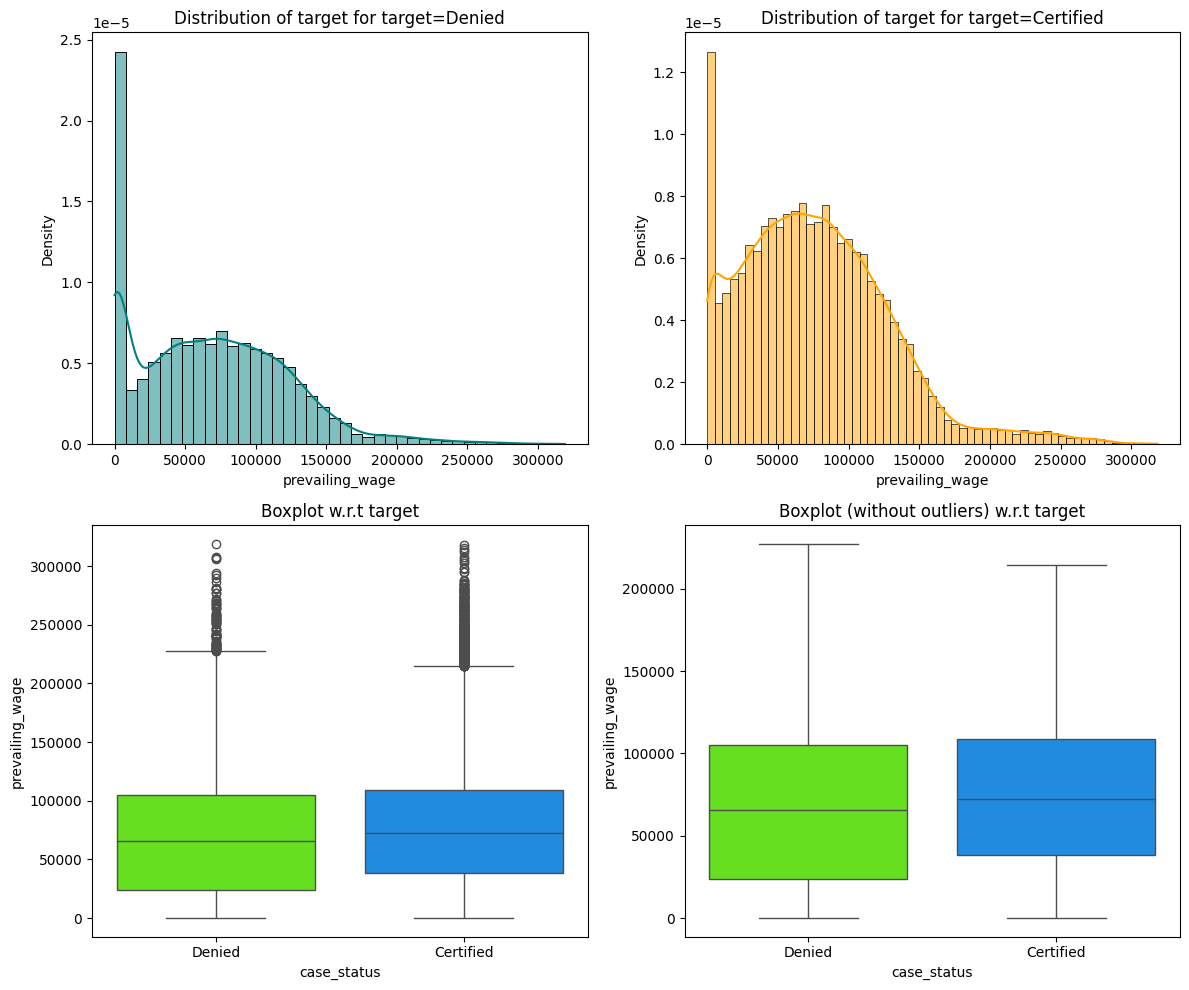

In [44]:
# Plot the distribution of 'prevailing_wage' with respect to 'case_status' to understand their relationship
distribution_plot_wrt_target(data, 'prevailing_wage', 'case_status')

* Certified cases generally have higher prevailing wages than Denied cases.
* Both Denied and Certified wage distributions are right-skewed, with some very high-pay outliers.

#### Case Status vs Year of Establishment

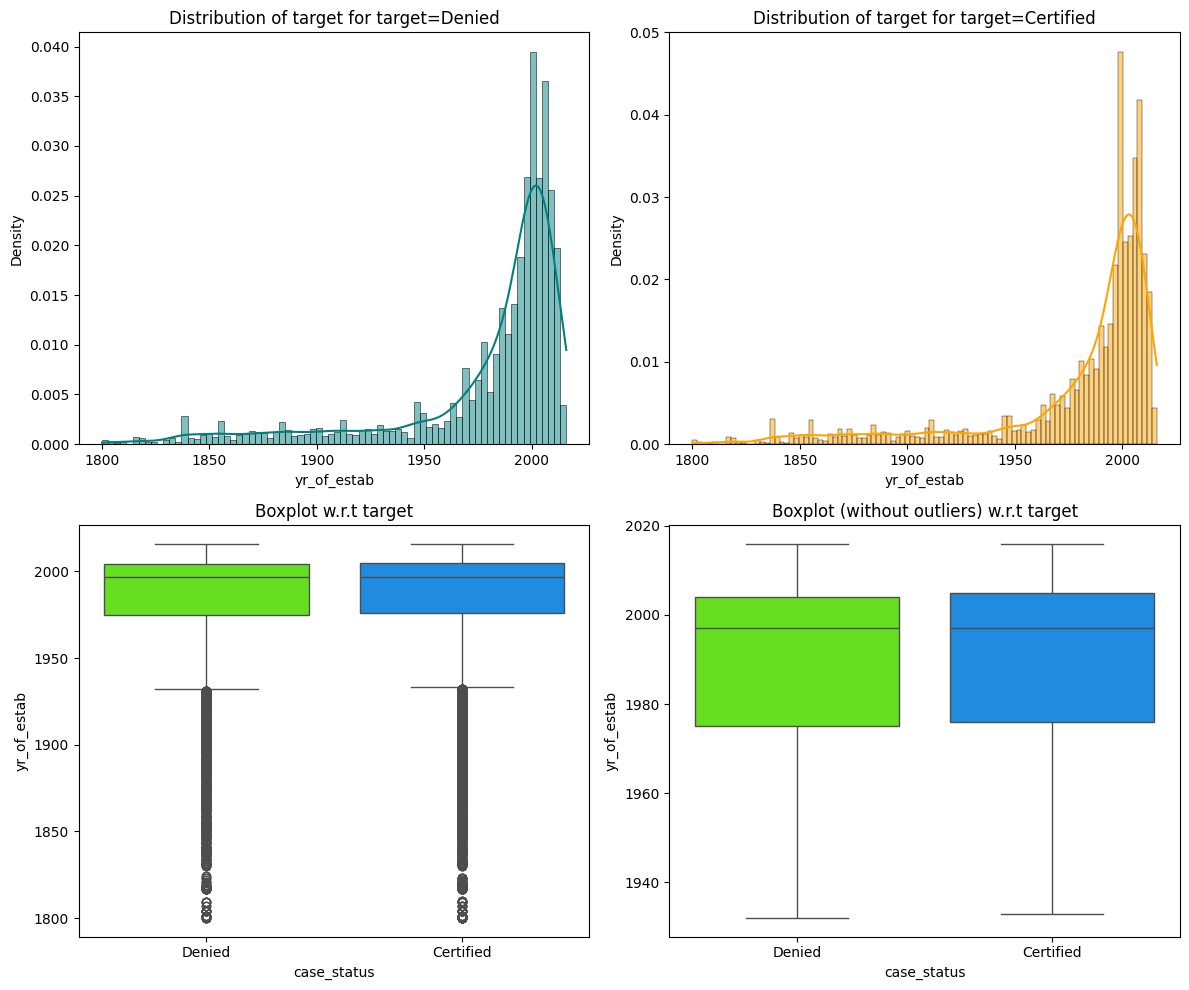

In [45]:
# Plot the distribution of 'yr_of_estab' with respect to 'case_status' to understand their relationship
distribution_plot_wrt_target(data, 'yr_of_estab', 'case_status')

* Most companies, for both Denied and Certified cases, were established after 1950.
* Certified cases tend to be from slightly newer companies compared to Denied cases.
* The difference in establishment year between Denied and Certified cases is small, indicating a weak impact on case outcome

### Data Preparation for Modeling

In [46]:
# Strip whitespace and title case the 'continent' column for consistency
data['continent'] = data['continent'].str.strip().str.title()
# Perform one-hot encoding on the 'continent' column and drop the first category to avoid multicollinearity
data = pd.get_dummies(data, columns=['continent'], drop_first=True)

In [47]:
education_map = {
    'High School': 1,
    "Bachelor's": 2,
    "Master's": 3,
    'Doctorate': 4
}

# Fill any missing values in 'education_of_employee' with the mode before mapping
data['education_of_employee'].fillna(
    data['education_of_employee'].mode()[0],
    inplace=True
)
# Map education levels to numerical values based on the defined dictionary
data['education_of_employee'] = data['education_of_employee'].map(education_map)


In [48]:
# Map 'Y' to 1 and 'N' to 0 for the 'has_job_experience' column
data['has_job_experience'] = data['has_job_experience'].map({'Y':1, 'N':0})

In [49]:
# Map 'Y' to 1 and 'N' to 0 for the 'requires_job_training' column
data['requires_job_training'] = data['requires_job_training'].map({'Y':1, 'N':0})

In [50]:
# Perform one-hot encoding on 'region_of_employment' and drop the first category
data = pd.get_dummies(
    data,
    columns=['region_of_employment'],
    drop_first=True
)

In [51]:
# The 40-hour workweek assumption is based on widely accepted labor standards for full-time employment.
# Commonly used in compensation analysis to annualize hourly wages.
# Convert hourly wage to yearly wage (40 hours/week * 52 weeks/year = 2080 hours/year)
data.loc[data['unit_of_wage'] == 'Hour', 'prevailing_wage'] *= 2080

# Convert weekly wage to yearly wage (52 weeks/year)
# The assumption of 52 weeks is based on the standard calendar year and is commonly used in compensation analysis to estimate annual earnings.
data.loc[data['unit_of_wage'] == 'Week', 'prevailing_wage'] *= 52

# Convert monthly wage to yearly wage (12 months/year)
data.loc[data['unit_of_wage'] == 'Month', 'prevailing_wage'] *= 12

In [52]:
# Perform one-hot encoding on 'unit_of_wage' and drop the first category
data = pd.get_dummies(
    data,
    columns=['unit_of_wage'],
    drop_first=True
)


In [53]:
# Map 'Y' to 1 and 'N' to 0 for the 'full_time_position' column
data['full_time_position'] = data['full_time_position'].map({'Y':1, 'N':0})

In [54]:
# Map 'Certified' to 1 and 'Denied' to 0 for the 'case_status' column
data['case_status'] = data['case_status'].map(
    {'Certified':1,
    'Denied':0
})


In [55]:
# Filter out rows where 'no_of_employees' is not positive (invalid values)
data = data[data['no_of_employees'] > 0]  # keep only valid values
# No outlier capping applied


In [56]:
# Filter out 'yr_of_estab' values outside a reasonable range (1900-2025)
data = data[(data['yr_of_estab'] >= 1900) & (data['yr_of_estab'] <= 2025)]
# Calculate 'company_age' based on 'yr_of_estab' and the current year (2025)
data['company_age'] = 2025 - data['yr_of_estab']
# Drop the original 'yr_of_estab' column as 'company_age' is created
data.drop(columns=['yr_of_estab'], inplace=True)


In [57]:
# Display the first few rows of the preprocessed DataFrame
data.head()

,education_of_employee,has_job_experience,requires_job_training,no_of_employees,prevailing_wage,full_time_position,case_status,continent_Asia,continent_Europe,continent_North America,continent_Oceania,continent_South America,region_of_employment_Midwest,region_of_employment_Northeast,region_of_employment_South,region_of_employment_West,unit_of_wage_Month,unit_of_wage_Week,unit_of_wage_Year,company_age
0,1,0,0,14513,1231782.032,1,0,True,False,False,False,False,False,False,False,True,False,False,False,18
1,3,1,0,2412,83425.650,1,1,True,False,False,False,False,False,True,False,False,False,False,True,23
2,2,0,1,44444,122996.860,1,0,True,False,False,False,False,False,False,False,True,False,False,True,17
4,3,1,0,1082,149907.390,1,1,False,False,False,False,False,False,False,True,False,False,False,True,20
5,3,1,0,2339,78252.140,1,1,True,False,False,False,False,False,False,True,False,False,False,True,13


In [58]:
# Print a concise summary of the preprocessed DataFrame, including data types and non-null values
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 23339 entries, 0 to 25479
Data columns (total 20 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   education_of_employee           23339 non-null  int64  
 1   has_job_experience              23339 non-null  int64  
 2   requires_job_training           23339 non-null  int64  
 3   no_of_employees                 23339 non-null  int64  
 4   prevailing_wage                 23339 non-null  float64
 5   full_time_position              23339 non-null  int64  
 6   case_status                     23339 non-null  int64  
 7   continent_Asia                  23339 non-null  bool   
 8   continent_Europe                23339 non-null  bool   
 9   continent_North America         23339 non-null  bool   
 10  continent_Oceania               23339 non-null  bool   
 11  continent_South America         23339 non-null  bool   
 12  region_of_employment_Midwest    23339

In [59]:
# Separate features (X) and target (y) variables
X = data.drop(["case_status"], axis=1)
y = data["case_status"]

# Splitting data into training, validation and test set:
# First, split data into 2 parts: temporary (for train and validation) and test
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1, stratify=y
)

# Then, split the temporary set into train and validation
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=1, stratify=y_temp
)
print(X_train.shape, X_val.shape, X_test.shape)

(14003, 19) (4668, 19) (4668, 19)


In [60]:
print("Number of rows in train data =", X_train.shape[0])
print("Number of rows in validation data =", X_val.shape[0])
print("Number of rows in test data =", X_test.shape[0])

Number of rows in train data = 14003
Number of rows in validation data = 4668
Number of rows in test data = 4668


In [61]:
# Check for missing values in training, validation, and test sets
print(X_train.isna().sum())
print("-" * 50)
print(X_val.isna().sum())
print("-" * 50)
print(X_test.isna().sum())

education_of_employee             0
has_job_experience                0
requires_job_training             0
no_of_employees                   0
prevailing_wage                   0
full_time_position                0
continent_Asia                    0
continent_Europe                  0
continent_North America           0
continent_Oceania                 0
continent_South America           0
region_of_employment_Midwest      0
region_of_employment_Northeast    0
region_of_employment_South        0
region_of_employment_West         0
unit_of_wage_Month                0
unit_of_wage_Week                 0
unit_of_wage_Year                 0
company_age                       0
dtype: int64
--------------------------------------------------
education_of_employee             0
has_job_experience                0
requires_job_training             0
no_of_employees                   0
prevailing_wage                   0
full_time_position                0
continent_Asia                    0


In [62]:
# Print a concise summary of the final DataFrame, including data types and non-null values
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 23339 entries, 0 to 25479
Data columns (total 20 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   education_of_employee           23339 non-null  int64  
 1   has_job_experience              23339 non-null  int64  
 2   requires_job_training           23339 non-null  int64  
 3   no_of_employees                 23339 non-null  int64  
 4   prevailing_wage                 23339 non-null  float64
 5   full_time_position              23339 non-null  int64  
 6   case_status                     23339 non-null  int64  
 7   continent_Asia                  23339 non-null  bool   
 8   continent_Europe                23339 non-null  bool   
 9   continent_North America         23339 non-null  bool   
 10  continent_Oceania               23339 non-null  bool   
 11  continent_South America         23339 non-null  bool   
 12  region_of_employment_Midwest    23339

## Model Building

### Model Evaluation Criterion

  **Model can make wrong predictions as:**

  1. Predicting that a visa application will be Certified, but in reality, it gets Denied
→ Leads to wastage of processing time, administrative effort, and resources on cases that are unlikely to be approved.
  2. Predicting that a visa application will be Denied, but in reality, it would have been Certified
→ Leads to loss of skilled talent, delays in filling critical job roles, and missed business opportunities for U.S. employers.

  **Which case is more important?**
  * Incorrectly denying a visa application that would have been approved is more critical, as it results in the loss of qualified and deserving candidates, negatively impacting businesses facing workforce shortages.

  **How to reduce this loss i.e need to reduce False Negatives?**

  * The model should aim to maximize Recall for the Certified class, as higher recall ensures that most genuinely approvable visa applications are correctly identified.
  * By focusing on improving Recall, the model minimizes false negatives, thereby reducing the chances of rejecting eligible candidates who have a high likelihood of visa approval.

First, let's create functions to calculate different metrics and confusion matrix so that we don't have to use the same code repeatedly for each model.

* The model_performance_classification_sklearn function will be used to check the model performance of models.
* The confusion_matrix_sklearnfunction will be used to plot confusion matrix.

In [63]:
# Defining a function to compute different metrics to check performance of a classification model built using sklearn
def model_performance_classification_sklearn(model, predictors, target):
    """
    Function to compute different metrics to check classification model performance

    model: classifier
    predictors: independent variables
    target: dependent variable
    """

    # Predicting using the independent variables
    pred = model.predict(predictors)

    acc = accuracy_score(target, pred)  # to compute Accuracy
    recall = recall_score(target, pred)  # to compute Recall
    precision = precision_score(target, pred)  # to compute Precision
    f1 = f1_score(target, pred)  # to compute F1-score

    # Creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {"Accuracy": acc, "Recall": recall, "Precision": precision, "F1": f1,},
        index=[0],
    )

    return df_perf

In [64]:
def confusion_matrix_sklearn(model, predictors, target):
    """
    To plot the confusion_matrix with percentages

    model: classifier
    predictors: independent variables
    target: dependent variable
    """
    y_pred = model.predict(predictors)
    cm = confusion_matrix(target, y_pred)
    labels = np.asarray(
        [
            ["{0:0.0f}".format(item) + "\n{0:.2%}".format(item / cm.flatten().sum())]
            for item in cm.flatten()
        ]
    ).reshape(2, 2)

    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=labels, fmt="")
    plt.ylabel("True label")
    plt.xlabel("Predicted label")
    plt.xlabel("Predicted label")

## Initial Model Building

### Configure the models

In [65]:
# configure all the required models
model_dict = {
    "Bagging": BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=1, class_weight="balanced"),
        random_state=1
    ),
    "Random Forest": RandomForestClassifier(
        random_state=1,
        class_weight="balanced"
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Decision Tree": DecisionTreeClassifier(
        random_state=1,
        class_weight="balanced"
    )
}
# append all the models
models = [(name, model) for name, model in model_dict.items()]

### Model Building - Original Data

In [66]:
print("\nTraining Performance:\n")
for name, model in models:
    # Train the model on original training data
    model.fit(X_train, y_train)
    # Calculate recall score on training data
    scores = recall_score(y_train, model.predict(X_train))
    print("{}: {}".format(name, scores))

print("\nValidation Performance:\n")
for name, model in models:
    # Train the model original validation data
    model.fit(X_train, y_train)
    # Calculate recall score on validation data
    scores_val = recall_score(y_val, model.predict(X_val))
    print("{}: {}".format(name, scores_val))


Training Performance:

Bagging: 0.9871781173202265
Random Forest: 1.0
Gradient Boosting: 0.8780852655198205
AdaBoost: 0.8905866011325997
Decision Tree: 1.0

Validation Performance:

Bagging: 0.7951923076923076
Random Forest: 0.8448717948717949
Gradient Boosting: 0.8701923076923077
AdaBoost: 0.8910256410256411
Decision Tree: 0.7490384615384615


* AdaBoost performs best on validation data, while Decision Tree and Random Forest overfit despite perfect training accuracy.

### Model Building - Oversampled Data

In [67]:
print("Before Oversampling, counts of label 'Yes': {}".format(sum(y_train == 1)))
print("Before Oversampling, counts of label 'No': {} \n".format(sum(y_train == 0)))

# Synthetic Minority Over Sampling Technique
sm = SMOTE(
    sampling_strategy=1, k_neighbors=5, random_state=1
)
X_train_over, y_train_over = sm.fit_resample(X_train, y_train)


print("After Oversampling, counts of label 'Yes': {}".format(sum(y_train_over == 1)))
print("After Oversampling, counts of label 'No': {} \n".format(sum(y_train_over == 0)))


print("After Oversampling, the shape of train_X: {}".format(X_train_over.shape))
print("After Oversampling, the shape of train_y: {} \n".format(y_train_over.shape))

Before Oversampling, counts of label 'Yes': 9359
Before Oversampling, counts of label 'No': 4644 

After Oversampling, counts of label 'Yes': 9359
After Oversampling, counts of label 'No': 9359 

After Oversampling, the shape of train_X: (18718, 19)
After Oversampling, the shape of train_y: (18718,) 



In [68]:
print("\n" "Training Performance:" "\n")
for name, model in models:
    # Train the model on oversampled training data
    model.fit(X_train_over, y_train_over)
    # Calculate recall score on training data
    scores = recall_score(y_train_over, model.predict(X_train_over))
    print("{}: {}".format(name, scores))

print("\n" "Validation Performance:" "\n")

for name, model in models:
    # Train the model on oversampled validation data
    model.fit(X_train_over, y_train_over)
    # Calculate recall score on validation data
    scores = recall_score(y_val, model.predict(X_val))
    print("{}: {}".format(name, scores))



Training Performance:

Bagging: 0.9820493642483171
Random Forest: 0.9998931509776685
Gradient Boosting: 0.8451757666417352
AdaBoost: 0.8187840581258682
Decision Tree: 1.0

Validation Performance:

Bagging: 0.7625
Random Forest: 0.8150641025641026
Gradient Boosting: 0.8368589743589744
AdaBoost: 0.8217948717948718
Decision Tree: 0.7407051282051282


In [69]:
print("\nTraining and Validation Performance Difference:\n")

#calculate the training score ,validation score and difference
for name, model in models:
    model.fit(X_train_over, y_train_over)
    scores_train = recall_score(y_train_over, model.predict(X_train_over))
    scores_val = recall_score(y_val, model.predict(X_val))
    difference2 = scores_train - scores_val
    print("{}: Training Score: {:.4f}, Validation Score: {:.4f}, Difference: {:.4f}".format(name, scores_train, scores_val, difference2))


Training and Validation Performance Difference:

Bagging: Training Score: 0.9820, Validation Score: 0.7625, Difference: 0.2195
Random Forest: Training Score: 0.9999, Validation Score: 0.8151, Difference: 0.1848
Gradient Boosting: Training Score: 0.8452, Validation Score: 0.8369, Difference: 0.0083
AdaBoost: Training Score: 0.8188, Validation Score: 0.8218, Difference: -0.0030
Decision Tree: Training Score: 1.0000, Validation Score: 0.7407, Difference: 0.2593


* GBM is best because it performs almost the same on training and validation data, showing good generalization.

### Model Building - Undersampled Data

In [70]:
random_un = RandomUnderSampler(random_state=1)
X_train_un, y_train_un = random_un.fit_resample(X_train, y_train)

In [71]:
print("Before Under Sampling, counts of label 'Yes': {}".format(sum(y_train == 1)))
print("Before Under Sampling, counts of label 'No': {} \n".format(sum(y_train == 0)))

print("After Under Sampling, counts of label 'Yes': {}".format(sum(y_train_un == 1)))
print("After Under Sampling, counts of label 'No': {} \n".format(sum(y_train_un == 0)))

print("After Under Sampling, the shape of train_X: {}".format(X_train_un.shape))
print("After Under Sampling, the shape of train_y: {} \n".format(y_train_un.shape))

Before Under Sampling, counts of label 'Yes': 9359
Before Under Sampling, counts of label 'No': 4644 

After Under Sampling, counts of label 'Yes': 4644
After Under Sampling, counts of label 'No': 4644 

After Under Sampling, the shape of train_X: (9288, 19)
After Under Sampling, the shape of train_y: (9288,) 



In [72]:
print("\n" "Training Performance:" "\n")
for name, model in models:
    # Train the model on under sampled training data
    model.fit(X_train_un, y_train_un)
    # Calculate recall score on training data
    scores = recall_score(y_train_un, model.predict(X_train_un))
    print("{}: {}".format(name, scores))

print("\n" "Validation Performance:" "\n")

for name, model in models:
    # Train the model on under sampled validation data
    model.fit(X_train_un, y_train_un)
    # Calculate recall score on validation data
    scores = recall_score(y_val, model.predict(X_val))
    print("{}: {}".format(name, scores))


Training Performance:

Bagging: 0.9683462532299741
Random Forest: 1.0
Gradient Boosting: 0.7368647717484926
AdaBoost: 0.6909991386735572
Decision Tree: 1.0

Validation Performance:

Bagging: 0.6224358974358974
Random Forest: 0.676923076923077
Gradient Boosting: 0.7182692307692308
AdaBoost: 0.6913461538461538
Decision Tree: 0.6432692307692308


In [73]:
print("\nTraining and Validation Performance Difference:\n")

#calculate the training score ,validation score and difference
for name, model in models:
    model.fit(X_train_un, y_train_un)
    scores_train = recall_score(y_train_un, model.predict(X_train_un))
    scores_val = recall_score(y_val, model.predict(X_val))
    difference3 = scores_train - scores_val
    print("{}: Training Score: {:.4f}, Validation Score: {:.4f}, Difference: {:.4f}".format(name, scores_train, scores_val, difference3))


Training and Validation Performance Difference:

Bagging: Training Score: 0.9683, Validation Score: 0.6224, Difference: 0.3459
Random Forest: Training Score: 1.0000, Validation Score: 0.6769, Difference: 0.3231
Gradient Boosting: Training Score: 0.7369, Validation Score: 0.7183, Difference: 0.0186
AdaBoost: Training Score: 0.6910, Validation Score: 0.6913, Difference: -0.0003
Decision Tree: Training Score: 1.0000, Validation Score: 0.6433, Difference: 0.3567


* The top three models overall are `AdaBoost (Original)` with a validation score of 0.891, `GBM (Original)` with 0.870, and `Random Forest (Original)` with 0.845, as they deliver the highest validation performance and generalize better than models trained on oversampled or undersampled data.

### Hyperparameter Tuning

#### Tuning AdaBoostClassifier model with Original Data

In [74]:
# Define the base estimator (Decision Tree) for AdaBoost
base_estimator = DecisionTreeClassifier(random_state=1)
# Initialize the AdaBoost classifier with the base estimator
Model = AdaBoostClassifier(
    estimator=base_estimator,
    random_state=1
)
# Define the hyperparameter search space for RandomizedSearchCV
param_grid = {
    "n_estimators": np.arange(50, 201, 25),        # Number of weak learners
    "learning_rate": [0.01, 0.05, 0.1, 0.2, 1],    # Contribution of each learner
    "estimator__max_depth": [1, 2]                 # Depth of the decision tree
}
# Define recall as the evaluation metric
scorer = make_scorer(recall_score)
# Initialize RandomizedSearchCV for hyperparameter tuning
randomized_cv = RandomizedSearchCV(
    estimator=Model,
    param_distributions=param_grid,
    n_iter=20,
    scoring=scorer,
    cv=5,
    n_jobs=-1,
    random_state=1,
    verbose=1
)
# Fit the model using training data
randomized_cv.fit(X_train, y_train)
# Print the best hyperparameters and corresponding CV recall score
print("Best parameters are {} with CV score={}:".format(randomized_cv.best_params_, randomized_cv.best_score_))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best parameters are {'n_estimators': np.int64(100), 'learning_rate': 0.01, 'estimator__max_depth': 1} with CV score=0.984188034188034:


In [75]:
# Initialize the tuned AdaBoost classifier with optimal hyperparameters
tuned_adaboost = AdaBoostClassifier(
    random_state=1,
    n_estimators=100,
    learning_rate=0.01,
    estimator=DecisionTreeClassifier(
        max_depth=1,
        random_state=1
    )
)

# Train the tuned AdaBoost model on the training data
tuned_adaboost.fit(X_train, y_train)


AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1,
                                                    random_state=1),
                   learning_rate=0.01, n_estimators=100, random_state=1)

In [76]:
# Checking model's performance on training set
adb_train = model_performance_classification_sklearn(tuned_adaboost, X_train, y_train)
adb_train

,Accuracy,Recall,Precision,F1
0,0.668357,1.0,0.668357,0.801216


In [77]:
# Checking model's performance on validation set
adb_val = model_performance_classification_sklearn(tuned_adaboost, X_val, y_val)
adb_val

,Accuracy,Recall,Precision,F1
0,0.66838,1.0,0.66838,0.801233


#### Tuning GBM model with Original Data

In [78]:
#defining model
Model = GradientBoostingClassifier(random_state=1)

#Parameter grid to pass in RandomSearchCV
param_grid = {
    "init": [AdaBoostClassifier(random_state=1),DecisionTreeClassifier(random_state=1)],
    "n_estimators": np.arange(75,150,25),
    "learning_rate": [0.1, 0.01, 0.2, 0.05, 1],
    "subsample":[0.5,0.7,1],
    "max_features":[0.5,0.7,1],
}

# Type of scoring used to compare parameter combinations
scorer = make_scorer(recall_score)

#Calling RandomizedSearchCV
randomized_cv = RandomizedSearchCV(estimator=Model, param_distributions=param_grid, n_iter=50, scoring=scorer, cv=5, random_state=1, n_jobs = -1)

#Fitting parameters in RandomizedSearchCV
randomized_cv.fit(X_train, y_train)

print("Best parameters are {} with CV score={}:".format(randomized_cv.best_params_,randomized_cv.best_score_))

Best parameters are {'subsample': 0.5, 'n_estimators': np.int64(125), 'max_features': 1, 'learning_rate': 0.01, 'init': AdaBoostClassifier(random_state=1)} with CV score=0.9399508695473422:


In [79]:
tuned_gbm= GradientBoostingClassifier(
     random_state=1,
    subsample=0.5,
    n_estimators=125,
    max_features=1,
    learning_rate=0.01,
    init=AdaBoostClassifier(random_state=1),
)
tuned_gbm.fit(X_train, y_train)

GradientBoostingClassifier(init=AdaBoostClassifier(random_state=1),
                           learning_rate=0.01, max_features=1, n_estimators=125,
                           random_state=1, subsample=0.5)

In [80]:
# Checking model's performance on training set
gbm_train = model_performance_classification_sklearn(tuned_gbm, X_train, y_train)
gbm_train

,Accuracy,Recall,Precision,F1
0,0.721345,0.939737,0.724883,0.818444


In [81]:
# Checking model's performance on validation set
gbm_val = model_performance_classification_sklearn(tuned_gbm, X_val, y_val)
gbm_val

,Accuracy,Recall,Precision,F1
0,0.722793,0.941667,0.725432,0.819526


#### Tuning Random Forest model with Original Data

In [82]:
# Initialize the Random Forest classifier
rf_estimator = RandomForestClassifier(
    random_state=1,        # Ensures reproducible results
    n_jobs=-1              # Use all available CPU cores
)
# Define the hyperparameter search space for RandomizedSearchCV
param_grid = {
    "n_estimators": [150, 250, 350],
    "max_depth": [10, 20],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt"]
}
# Define recall as the scoring metric
scorer = make_scorer(recall_score)
# Initialize RandomizedSearchCV for hyperparameter tuning
randomized_cv = RandomizedSearchCV(
    estimator=rf_estimator,
    param_distributions=param_grid,
    n_iter=15,
    scoring=scorer,
    cv=3,
    random_state=1,
    verbose=1,
    n_jobs=-1
)
# Fit RandomizedSearchCV on the training data
randomized_cv.fit(X_train, y_train)
# Print the best hyperparameters and corresponding CV recall score
print("Best parameters are {} with CV recall score = {:.4f}".format(randomized_cv.best_params_, randomized_cv.best_score_)
)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best parameters are {'n_estimators': 350, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 10} with CV recall score = 0.8815


In [83]:
#use the best parameters to train the model
tuned_randomforest = RandomForestClassifier(
    random_state=1,
    n_estimators=350,
    min_samples_leaf=2,
    max_features='sqrt',
    max_depth=10
)
tuned_randomforest.fit(X_train, y_train)

RandomForestClassifier(max_depth=10, min_samples_leaf=2, n_estimators=350,
                       random_state=1)

In [84]:
# Checking model's performance on training set
randomforest_train = model_performance_classification_sklearn(tuned_randomforest, X_train, y_train)
randomforest_train

,Accuracy,Recall,Precision,F1
0,0.780333,0.904263,0.795171,0.846215


In [85]:
# Checking model's performance on validation set
randomforest_val = model_performance_classification_sklearn(tuned_randomforest, X_val, y_val)
randomforest_val

,Accuracy,Recall,Precision,F1
0,0.74593,0.875,0.774248,0.821547


### Model Comparison and Final Model Selection

In [86]:
# Training performance comparison

models_train_comp_df = pd.concat(
    [
        adb_train.T,
        gbm_train.T,
        randomforest_train.T
    ],
    axis=1,
)
models_train_comp_df.columns = [
    "AdaBoot trained with Original data",
    "Gradient boosting Original data",
    "Random Forest Original data",
]
print("Training performance comparison:")
models_train_comp_df

Training performance comparison:


,AdaBoot trained with Original data,Gradient boosting Original data,Random Forest Original data
Accuracy,0.668357,0.721345,0.780333
Recall,1.000000,0.939737,0.904263
Precision,0.668357,0.724883,0.795171
F1,0.801216,0.818444,0.846215


In [87]:
# Validation performance comparison

models_train_comp_df = pd.concat(
    [ adb_val.T, gbm_val.T, randomforest_val.T], axis=1,
)
models_train_comp_df.columns = [
    "AdaBoost trained with Original data",
    "Gradient boosting with Original data",
    "Ranndom Forest Original data",
]
print("Validation performance comparison:")
models_train_comp_df

Validation performance comparison:


,AdaBoost trained with Original data,Gradient boosting with Original data,Ranndom Forest Original data
Accuracy,0.668380,0.722793,0.745930
Recall,1.000000,0.941667,0.875000
Precision,0.668380,0.725432,0.774248
F1,0.801233,0.819526,0.821547


* On the original dataset, `Random Forest` demonstrated the best overall performance, achieving the highest accuracy and F1-score while maintaining strong recall,

### Feature Importance

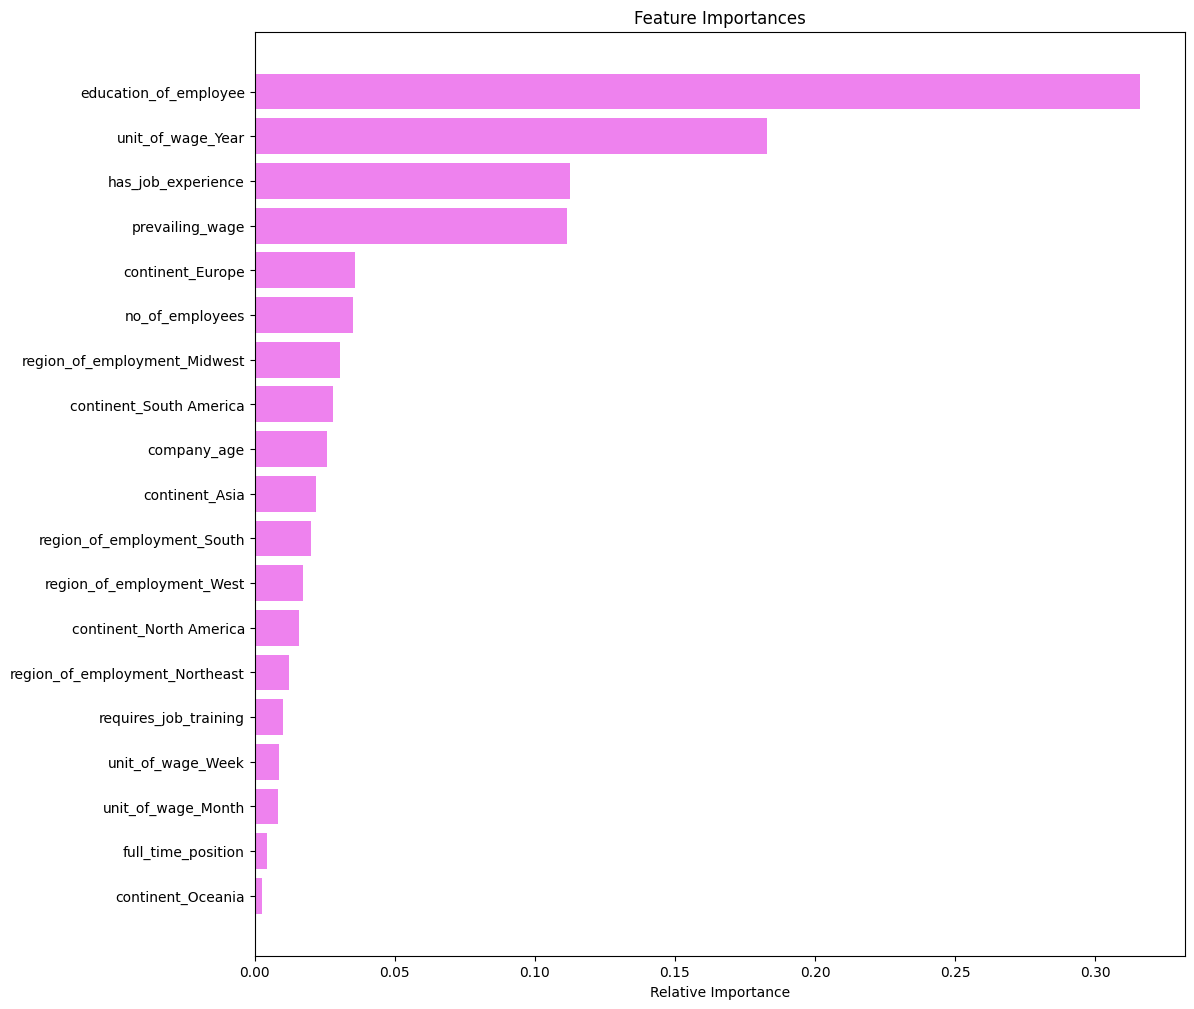

In [88]:
# Extract feature names from the training dataset
feature_names = X_train.columns

# Get feature importance scores from the trained Gradient Boosting model
importances = tuned_gbm.feature_importances_

# Sort feature indices based on importance values
indices = np.argsort(importances)

# Create a figure for the feature importance plot
plt.figure(figsize=(12, 12))
plt.title("Feature Importances")
plt.barh(range(len(indices)), importances[indices], color="violet", align="center")
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel("Relative Importance")
plt.show()

* Education of employee is the most influential feature, indicating that educational qualification plays a major role in visa approval decisions.
* Wage-related factors (unit_of_wage_Year, prevailing_wage) are among the top contributors, showing that salary structure and offered wage strongly impact outcomes.
* Job experience (has_job_experience) has high importance, suggesting experienced candidates are more likely to receive approvals.
* Overall, the model relies heavily on candidate qualifications and compensation, while location and job-type features play a secondary role.

### Business Insights and Recommendations

Based on the analysis of influential factors affecting visa certification, the following recommendations are provided for EasyVisa and visa applicants:

#### For EasyVisa:

1.  **Prioritize Highly Qualified Candidates**: Since `education_of_employee` is the most influential feature, EasyVisa should streamline and expedite the processing of applications from candidates with Master's and Doctorate degrees. These candidates have a significantly higher likelihood of certification.
2.  **Focus on Competitive Wage Positions**: Given the high importance of `prevailing_wage` and the higher certification rates for yearly wage units, EasyVisa could partner with employers who offer competitive wages and primarily offer yearly compensation. This would increase the overall success rate of applications they process.
3.  **Target Experienced Professionals**: `has_job_experience` is a strong predictor of certification. EasyVisa should actively market its services to experienced professionals and employers seeking such candidates, as these applications have better approval chances.
4.  **Geographical Strategy**: While Asia contributes the most applications, Europe shows the highest certification rates. EasyVisa could explore targeted outreach in European countries or regions within the US like the Midwest and South, which demonstrate higher approval rates, to maximize successful certifications.
5.  **Utilize Predictive Model**: Implement the developed predictive model within their application processing system to pre-screen applications. This will help in early identification of high-potential cases for fast-tracking.

#### For Visa Applicants:

1.  **Emphasize Education**: Applicants with higher education levels (Master's, Doctorate) have a significant advantage. If applicable, applicants should highlight advanced degrees and specialized qualifications prominently in their applications.
2.  **Seek Competitive Compensation**: The `prevailing_wage` is crucial. Applicants should aim for job offers with wages that meet or exceed the prevailing wage for their occupation and location. Additionally, year-based wage structures tend to have higher certification rates, so applicants should ideally seek jobs with yearly salaries.
3.  **Showcase Job Experience**: Extensive and relevant job experience is highly valued. Applicants should clearly articulate their work history, skills, and achievements to demonstrate their readiness for the job, as `has_job_experience` strongly influences outcomes.
4.  **Consider Employment Region**: While not the primary factor, knowing which regions have higher certification rates can be beneficial. Applicants might consider opportunities in regions like the Midwest or South if their skills are in demand there, potentially improving their chances.
5.  **No Job Training Needed**: While `requires_job_training` has low impact, it's generally better if the applicant does not require job training, indicating they are ready to contribute immediately.

By following these recommendations, both EasyVisa can optimize its operations and visa applicants can enhance their profiles to increase the likelihood of successful visa certification.

In [89]:
!jupyter nbconvert --to html "/content/AIML_ML_Project_Solution_Notebook (3).ipynb"

[NbConvertApp] Converting notebook /content/AIML_ML_Project_Solution_Notebook (3).ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 21 image(s).
[NbConvertApp] Writing 1430466 bytes to /content/AIML_ML_Project_Solution_Notebook (3).html
